# Cybertron-Interp: Mechanistic Interpretability Notebook

> **Prerequisite Note:** Following along with our readme this notebook covers the core code components for configuration and execution.

In [15]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import circuitsvis as cv
from transformers import GPT2LMHeadModel, GPT2Tokenizer

# 1. We are using OpenAI's GPT2 to conduct this project.  Since it is more basic we are able to more easily interpet its cognitive output.  
# To get exposed to additional information we set the model config to eager
# To speed up operatoins we are using an Nvidia GPU and Pytorch's GPU enabled config

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_id = "gpt2"  # we set the model gpt2 as our model
tokenizer = GPT2Tokenizer.from_pretrained(model_id) 
model = GPT2LMHeadModel.from_pretrained(model_id, attn_implementation="eager").to(device)
model.eval()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [23]:
# 2. Then we are going to send a prompt to test our Transformer trivia expert
prompt = "Optimus Prime is the leader"

# we want to instruct the tokenizer to return its tensors as Pytorch
inputs = tokenizer(prompt, return_tensors="pt").to(device)
tokens = [tokenizer.decode([t]) for t in inputs["input_ids"][0]]

with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

# Stack attention weights: [num_layers, batch, heads, q_pos, k_pos]
all_attentions = torch.stack(outputs.attentions)
print(f"Prompt tokens: {tokens}")
print(f"Attention tensor shape: {all_attentions.shape}")

Prompt tokens: ['Opt', 'imus', ' Prime', ' is', ' the', ' leader']
Attention tensor shape: torch.Size([12, 1, 12, 6, 6])


In [17]:
# 3. Interactive CircuitsVis view (Layer 11, all heads)
display(cv.attention.attention_patterns(
    tokens=tokens,
    attention=all_attentions[11, 0]
))

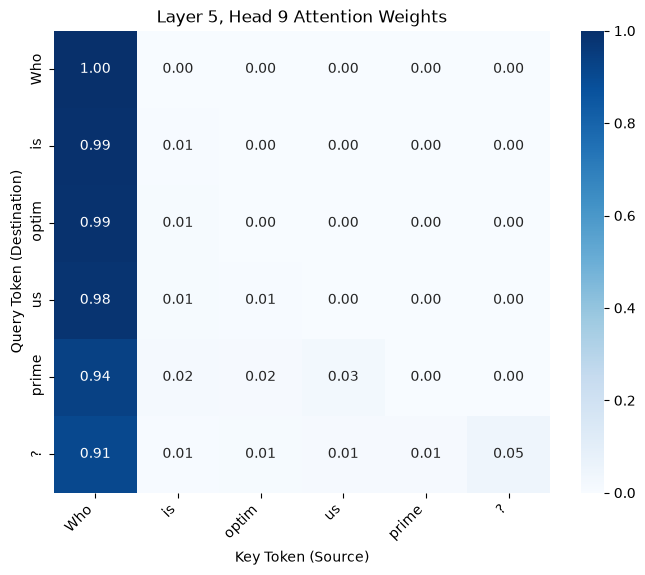

In [18]:
# 4. Seaborn heatmap for a single head (Layer 5, Head 9)
matrix = all_attentions[5, 0, 9].detach().cpu().numpy()
plt.figure(figsize=(8, 6))
sns.heatmap(matrix, xticklabels=tokens, yticklabels=tokens, annot=True, fmt=".2f", cmap="Blues")
plt.title("Layer 5, Head 9 Attention Weights")
plt.xlabel("Key Token (Source)")
plt.ylabel("Query Token (Destination)")
plt.xticks(rotation=45, ha="right")
plt.show()

In [24]:
# 5. Generate a completion to see how the model responds to the prompt
inputs = tokenizer(prompt, return_tensors="pt")
input_ids = inputs["input_ids"].to(device)

with torch.no_grad():
    output_ids = model.generate(
        input_ids,
        max_new_tokens=20,
        do_sample=True,
        temperature=0.7,
        repetition_penalty=1.2,
        pad_token_id=tokenizer.eos_token_id
    )

response_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
print(f"Model Response:\n{response_text}")

Model Response:
Optimus Prime is the leader of a new series called Optimus Uprising, where he and his Autobots are given missions by both
